# Bước 5 - Phân tích khám phá dữ liệu (EDA)

**Mục tiêu:** hiểu dữ liệu sạch và thu thập luận điểm cho phần Insight. Mỗi phát hiện là **một câu có số liệu** gắn với **một biểu đồ**.

**Dữ liệu:** `data/final/clean_features.parquet` (X), `data/final/clean_labels.parquet` (y) và `data/processed/clean_audit.parquet`
(dinh dưỡng + điểm, **chỉ dùng để EDA và để chứng minh rò rỉ**, không bao giờ làm đặc trưng).

**Cách đọc:** các con số trong câu kết luận được tính trực tiếp từ dữ liệu bằng mã ngay phía trên, nên chạy lại notebook là số cập nhật theo.
Hạng A-E là dữ liệu có thứ tự nên dùng một dải màu xanh từ nhạt (A) đến đậm (E).

In [1]:
import os
import re
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)
(ROOT / "reports" / "figures").mkdir(parents=True, exist_ok=True)

# --- Bảng màu và kiểu chữ (giá trị lấy từ bảng màu chuẩn) -------------------------------
SURFACE, INK, INK2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
GRADES = list("abcde")
ORD = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281"]   # hạng A..E, nhạt -> đậm
ORD_TXT = [INK, INK, "#ffffff", "#ffffff", "#ffffff"]           # màu chữ đặt trong ô tô màu
CAT = ["#2a78d6", "#eb6834", "#1baf7a"]                         # 3 màu phân loại đầu tiên
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "text.color": INK, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.edgecolor": MUTED, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.family": ["Segoe UI", "DejaVu Sans"], "font.size": 10, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "figure.dpi": 100,
})


def vn(x, d=1):
    """Số kiểu Việt Nam: dấu phẩy thập phân."""
    return f"{x:.{d}f}".replace(".", ",")


def vi(n):
    """Số nguyên kiểu Việt Nam: dấu chấm ngăn nghìn."""
    return f"{int(n):,}".replace(",", ".")


def save(fig, name):
    fig.savefig(ROOT / "reports" / "figures" / f"{name}.png", dpi=130, bbox_inches="tight")
    plt.show()


def cramers_v(ct):
    chi2, p, _, _ = stats.chi2_contingency(ct)
    return chi2, p, float(np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1))))


def stacked_h(ax, pct, labels=None):
    """Thanh chồng 100% nằm ngang; mỗi hàng của pct là một thanh, cột là hạng A..E."""
    for i, (idx, row) in enumerate(pct.iterrows()):
        left = 0.0
        for k, g in enumerate(GRADES):
            w = row[g]
            ax.barh(i, w, left=left, color=ORD[k], edgecolor=SURFACE, linewidth=1.5, height=0.62)
            if w >= 4:
                ax.text(left + w / 2, i, f"{w:.0f}%", ha="center", va="center", color=ORD_TXT[k], fontsize=9)
            left += w
    ax.set_yticks(range(len(pct)))
    ax.set_yticklabels(labels or list(pct.index))
    ax.invert_yaxis()
    ax.set_xlim(0, 100)
    ax.set_xlabel("% sản phẩm")
    ax.grid(axis="y", visible=False)
    ax.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in ORD], [g.upper() for g in GRADES],
              title="Hạng", ncol=5, loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False, fontsize=9)


FINDINGS = []


def finding(text):
    FINDINGS.append(text)
    print(f"PHÁT HIỆN {len(FINDINGS)}: {text}")

In [2]:
X = pd.read_parquet("data/final/clean_features.parquet")
y = pd.read_parquet("data/final/clean_labels.parquet")
A = pd.read_parquet("data/processed/clean_audit.parquet")
d = (X.merge(y[["row_id", "nutriscore_grade"]], on="row_id")
       .merge(A.drop(columns=["code", "nutriscore_grade", "nutriscore_grade_raw"]), on="row_id"))
d["g"] = d["nutriscore_grade"].map({k: i for i, k in enumerate(GRADES)})
N = len(d)
assert N == len(X) == len(y) == len(A), "ba bảng phải cùng số dòng"

# Nhóm quốc gia theo CLAUDE.md: Mỹ, Pháp, còn lại. Sản phẩm bán ở cả hai nước (Mỹ+Pháp) tách riêng để các nhóm không chồng nhau.
us = d["countries_tags"].map(lambda v: v is not None and "en:united-states" in v)
fr = d["countries_tags"].map(lambda v: v is not None and "en:france" in v)
d["region"] = np.select([us & ~fr, fr & ~us, ~us & ~fr], ["Mỹ", "Pháp", "Còn lại"], default="Mỹ+Pháp")
REGIONS = ["Mỹ", "Pháp", "Còn lại"]

print(f"{vi(N)} sản phẩm | {X.shape[1]} cột đặc trưng | {A.shape[1]} cột audit")
print(d["region"].value_counts().to_string())
d.head(3).T.head(12)

29.904 sản phẩm | 27 cột đặc trưng | 15 cột audit
region
Mỹ         11150
Còn lại    10117
Pháp        8516
Mỹ+Pháp      121


,0,1,2
row_id,0,1,2
code,0051500825631,7610198074344,3222476292353
group_id,brand:smuckers-uncrustables,brand:volg,brand:casino
product_name,Peanut Butter & Strawberry Jam Sandwich,Caffè Latte Zero,Taboulé oriental
brand,smuckers-uncrustables,volg,casino
brands_tags,[smuckers-uncrustables],[volg],[casino]
countries_tags,[en:united-states],[en:switzerland],[en:france]
n_countries,1,1,1
categories_tags,[en:meals],"[en:plant-based-foods-and-beverages, en:bevera...","[en:meals, en:fresh-foods, en:savory-semolina-..."
pnns_groups_1,composite foods,beverages,composite foods


## 1. Phân bố nhãn A-E và mức mất cân bằng

Mất cân bằng lớp quyết định cách đo (F1 trung bình theo lớp, không dùng độ chính xác thuần) và có cần trọng số lớp hay không.

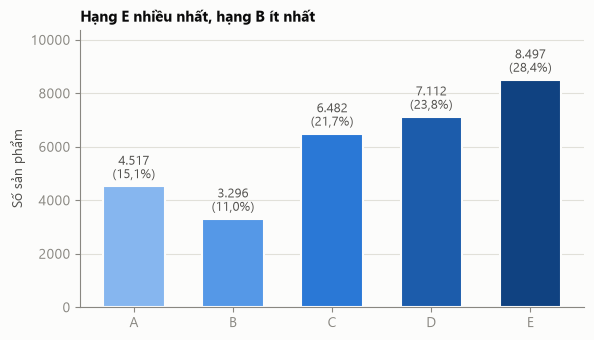

PHÁT HIỆN 1: Trong 29.904 sản phẩm, hạng E chiếm nhiều nhất (28,4%, 8.497 sản phẩm) và hạng B ít nhất (11,0%, 3.296); lớp lớn nhất gấp 2,6 lần lớp nhỏ nhất, mất cân bằng nhẹ nên dùng trọng số lớp và F1 trung bình theo lớp.


,số dòng,%
nutriscore_grade,,
a,4517,15.1
b,3296,11.0
c,6482,21.7
d,7112,23.8
e,8497,28.4


In [3]:
cnt = d["nutriscore_grade"].value_counts().reindex(GRADES)
pct = 100 * cnt / N
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.bar([g.upper() for g in GRADES], cnt.values, color=ORD, width=0.62, edgecolor=SURFACE, linewidth=1.5)
for i, (c, p) in enumerate(zip(cnt.values, pct.values)):
    ax.text(i, c + N * 0.006, f"{vi(c)}\n({vn(p)}%)", ha="center", va="bottom", fontsize=9, color=INK2)
ax.set_ylim(0, cnt.max() * 1.22)
ax.set_ylabel("Số sản phẩm")
ax.set_title("Hạng E nhiều nhất, hạng B ít nhất")
ax.grid(axis="x", visible=False)
save(fig, "eda_01_phan_bo_nhan")

top, low = pct.idxmax(), pct.idxmin()
ratio = cnt.max() / cnt.min()
finding(f"Trong {vi(N)} sản phẩm, hạng {top.upper()} chiếm nhiều nhất ({vn(pct[top])}%, {vi(cnt[top])} sản phẩm) và hạng "
        f"{low.upper()} ít nhất ({vn(pct[low])}%, {vi(cnt[low])}); lớp lớn nhất gấp {vn(ratio)} lần lớp nhỏ nhất, "
        f"mất cân bằng nhẹ nên dùng trọng số lớp và F1 trung bình theo lớp.")
pd.DataFrame({"số dòng": cnt, "%": pct.round(1)})

## 2. Nhãn theo quốc gia (Mỹ, Pháp, còn lại)

Nhãn Nutri-Score của sản phẩm Mỹ không in trên bao bì mà do Open Food Facts tự tính, nên cần xem phân bố có lệch không trước khi tin kết quả chung.

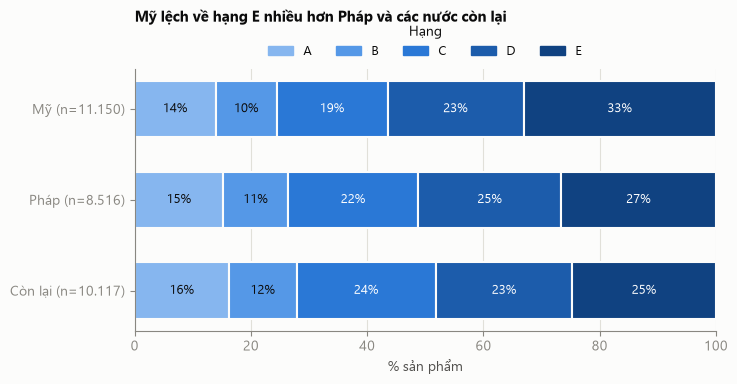

PHÁT HIỆN 2: Tỷ lệ hạng E là 33,0% ở Mỹ, 26,6% ở Pháp và 24,7% ở nhóm còn lại; khác biệt có ý nghĩa thống kê (chi-bình phương p<0,001) nhưng mức liên hệ nhỏ (Cramér's V = 0,063). 121 sản phẩm bán ở cả hai nước được loại khỏi phép so sánh này.


nutriscore_grade,a,b,c,d,e
region,,,,,
Mỹ,14.0,10.5,19.0,23.5,33.0
Pháp,15.3,11.1,22.4,24.6,26.6
Còn lại,16.3,11.6,24.0,23.4,24.7


In [4]:
ct = pd.crosstab(d["region"], d["nutriscore_grade"]).reindex(REGIONS)[GRADES]
pct_r = 100 * ct.div(ct.sum(axis=1), axis=0)
fig, ax = plt.subplots(figsize=(7.5, 3.4))
stacked_h(ax, pct_r, [f"{r} (n={vi(ct.loc[r].sum())})" for r in REGIONS])
ax.set_title("Mỹ lệch về hạng E nhiều hơn Pháp và các nước còn lại", pad=34)
save(fig, "eda_02_nhan_theo_quoc_gia")

chi2, p, V = cramers_v(ct)
n_both = int((d["region"] == "Mỹ+Pháp").sum())
finding(f"Tỷ lệ hạng E là {vn(pct_r.loc['Mỹ','e'])}% ở Mỹ, {vn(pct_r.loc['Pháp','e'])}% ở Pháp và {vn(pct_r.loc['Còn lại','e'])}% ở nhóm còn lại; "
        f"khác biệt có ý nghĩa thống kê (chi-bình phương p<0,001) nhưng mức liên hệ nhỏ (Cramér's V = {vn(V, 3)}). "
        f"{n_both} sản phẩm bán ở cả hai nước được loại khỏi phép so sánh này.")
assert p < 0.001
pct_r.round(1)

## 3. Nhãn theo nhóm danh mục (`pnns_groups_1`)

Danh mục sản phẩm là đặc trưng mạnh nhất có thể kỳ vọng; heatmap cho thấy nhóm nào gần như "đã biết trước" hạng và nhóm nào lẫn lộn.

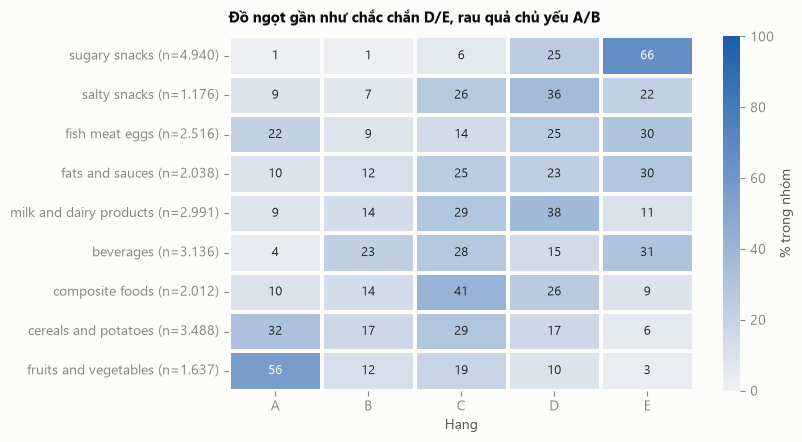

PHÁT HIỆN 3: Nhóm 'sugary snacks' có 91,5% sản phẩm hạng D/E trong khi nhóm 'fruits and vegetables' chỉ 12,8%; nhưng 5.966 sản phẩm (20,0%) không có `pnns_groups_1`, nên đặc trưng danh mục cần xử lý giá trị thiếu (dùng `categories_tags` bổ sung).


nutriscore_grade,a,b,c,d,e
pnns_groups_1,,,,,
sugary snacks,1.2,1.5,5.9,25.1,66.3
salty snacks,9.2,6.7,25.9,36.1,22.2
fish meat eggs,21.9,8.8,14.1,25.1,30.1
fats and sauces,9.6,12.4,25.1,23.2,29.7
milk and dairy products,8.7,13.7,29.3,37.7,10.7
beverages,3.7,22.8,27.9,14.5,31.1
composite foods,9.9,13.8,41.5,25.6,9.2
cereals and potatoes,31.7,16.6,29.2,16.8,5.8
fruits and vegetables,56.1,11.9,19.2,9.5,3.3


In [5]:
pn = d.dropna(subset=["pnns_groups_1"])
sizes = pn["pnns_groups_1"].value_counts()
keep = sizes[sizes >= 100].index                       # bỏ nhóm quá nhỏ (vd. alcoholic beverages n=4)
ct3 = pd.crosstab(pn["pnns_groups_1"], pn["nutriscore_grade"]).loc[keep][GRADES]
pct3 = 100 * ct3.div(ct3.sum(axis=1), axis=0)
de = (pct3["d"] + pct3["e"]).sort_values(ascending=False)
pct3 = pct3.loc[de.index]
fig, ax = plt.subplots(figsize=(7.5, 4.6))
sns.heatmap(pct3, annot=True, fmt=".0f", cmap=sns.light_palette("#1c5cab", as_cmap=True), vmin=0, vmax=100,
            linewidths=1.5, linecolor=SURFACE, cbar_kws={"label": "% trong nhóm"}, ax=ax,
            annot_kws={"fontsize": 9})
ax.set_xticklabels([g.upper() for g in GRADES], rotation=0)
ax.set_yticklabels([f"{k} (n={vi(sizes[k])})" for k in pct3.index], rotation=0)
ax.set_xlabel("Hạng"); ax.set_ylabel("")
ax.set_title("Đồ ngọt gần như chắc chắn D/E, rau quả chủ yếu A/B", pad=10)
save(fig, "eda_03_nhan_theo_nhom_danh_muc")

n_na = int(d["pnns_groups_1"].isna().sum())
finding(f"Nhóm '{de.index[0]}' có {vn(de.iloc[0])}% sản phẩm hạng D/E trong khi nhóm '{de.index[-1]}' chỉ {vn(de.iloc[-1])}%; "
        f"nhưng {vi(n_na)} sản phẩm ({vn(100 * n_na / N)}%) không có `pnns_groups_1`, nên đặc trưng danh mục cần xử lý giá trị thiếu (dùng `categories_tags` bổ sung).")
pct3.round(1)

## 4. Phân phối thành phần: đuôi dài

Mỗi thành phần là một cột đặc trưng tiềm năng. Nếu phần lớn thành phần hiếm đến mức chỉ xuất hiện vài lần, mô hình không học được gì từ chúng
và ta phải đặt ngưỡng tần suất tối thiểu ở Bước 6.

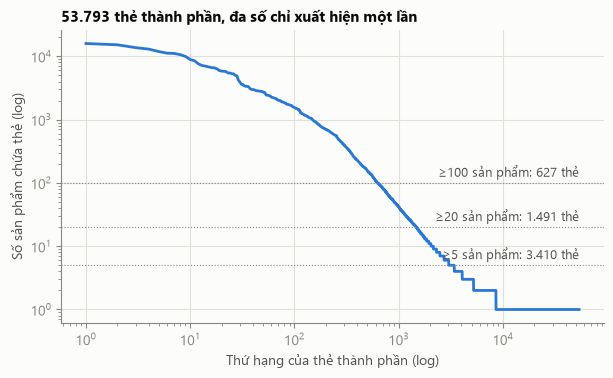

PHÁT HIỆN 4: Có 53.793 thẻ thành phần khác nhau, trong đó 84,1% chỉ xuất hiện đúng 1 lần và 93,7% dưới 5 lần; chỉ 1.491 thẻ có từ 20 sản phẩm và 627 thẻ từ 100 sản phẩm, nên Bước 6 cần ngưỡng tần suất tối thiểu (các thẻ ≥100 vẫn phủ 95,7% sản phẩm).


,số sản phẩm
en:salt,15965
en:added-sugar,15230
en:disaccharide,13735
en:sugar,13015
en:oil-and-fat,11905
en:vegetable-oil-and-fat,11232
en:water,11133
en:flavouring,10659
en:vegetable,9995
en:dairy,8913


In [6]:
tag_counts = Counter(t for tags in d["ingredients_tags"] for t in set(tags))
tc = pd.Series(tag_counts).sort_values(ascending=False)
n_tag = len(tc)
share_1, share_lt5 = (tc == 1).mean(), (tc < 5).mean()
n_ge20, n_ge100 = int((tc >= 20).sum()), int((tc >= 100).sum())
cover100 = d["ingredients_tags"].map(lambda t: any(tag_counts[x] >= 100 for x in t)).mean()

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(np.arange(1, n_tag + 1), tc.values, color=CAT[0], linewidth=2)
ax.set_xscale("log"); ax.set_yscale("log")
for thr, lab in ((100, "≥100 sản phẩm"), (20, "≥20 sản phẩm"), (5, "≥5 sản phẩm")):
    k = int((tc >= thr).sum())
    ax.axhline(thr, color=MUTED, linewidth=0.8, linestyle=":")
    ax.text(n_tag, thr * 1.12, f"{lab}: {vi(k)} thẻ", ha="right", va="bottom", fontsize=9, color=INK2)
ax.set_xlabel("Thứ hạng của thẻ thành phần (log)")
ax.set_ylabel("Số sản phẩm chứa thẻ (log)")
ax.set_title(f"{vi(n_tag)} thẻ thành phần, đa số chỉ xuất hiện một lần")
save(fig, "eda_04_duoi_dai_thanh_phan")

finding(f"Có {vi(n_tag)} thẻ thành phần khác nhau, trong đó {vn(100 * share_1)}% chỉ xuất hiện đúng 1 lần và {vn(100 * share_lt5)}% dưới 5 lần; "
        f"chỉ {vi(n_ge20)} thẻ có từ 20 sản phẩm và {vi(n_ge100)} thẻ từ 100 sản phẩm, "
        f"nên Bước 6 cần ngưỡng tần suất tối thiểu (các thẻ ≥100 vẫn phủ {vn(100 * cover100)}% sản phẩm).")
tc.head(10).rename("số sản phẩm").to_frame()

## 5. Thành phần và phụ gia nào kéo hạng xuống D/E?

**Lift** = P(D/E | có thành phần) / P(D/E) chung. Lift 1,8 nghĩa là sản phẩm chứa thành phần đó có khả năng D/E gấp 1,8 lần mức trung bình.
Vì D/E chiếm hơn một nửa dữ liệu nên lift tối đa chỉ khoảng 1,9. Đồ thị dùng log₂(lift) để hai phía (kéo xuống / kéo lên) cân xứng quanh 0.

**Lưu ý quan trọng:** lift chỉ là tương quan. Một thành phần có lift cao có thể chỉ vì nó hay nằm trong nhóm sản phẩm vốn xấu (kẹo, bánh), không phải vì nó "làm" xấu.
Ta kiểm tra điều này bên dưới.

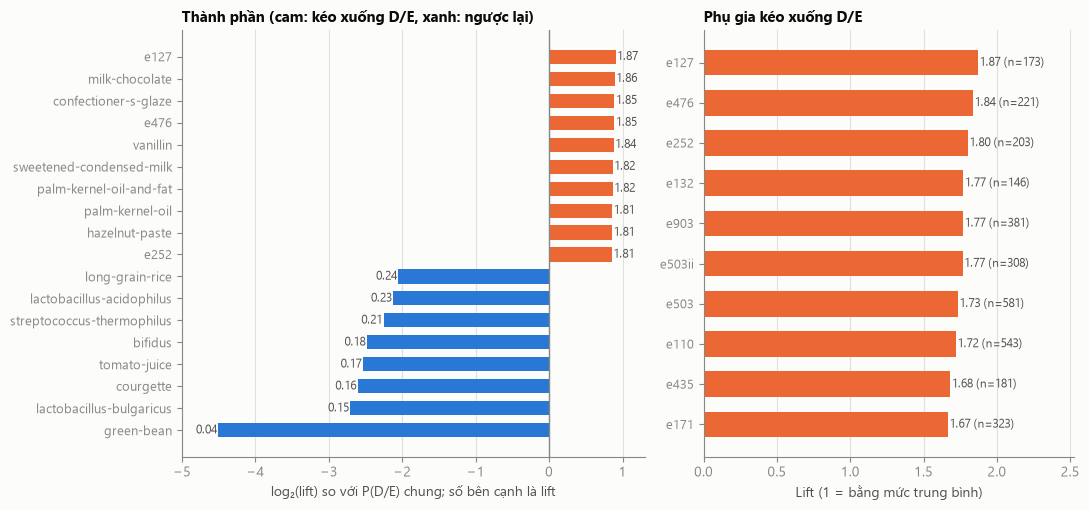

PHÁT HIỆN 5: Với P(D/E) chung = 52,2%, các thành phần có lift cao nhất gồm e127, milk-chocolate, confectioner-s-glaze (lift 1,87 đến 1,85), trong khi green-bean chỉ 0,04; phụ gia có lift cao nhất là e127 (1,87).
PHÁT HIỆN 6: Tuy nhiên 54,0% sản phẩm chứa 10 thành phần lift cao nhất thuộc nhóm 'sugary snacks', nên lift phản ánh một phần việc thành phần đó nằm trong đồ ngọt chứ chưa chứng minh nó tự kéo hạng xuống; cần phân tích SHAP trong từng nhóm ở Bước 9.


,n,p_de,lift
ingredients_tags,,,
en:e127,176,0.977,1.872
en:milk-chocolate,458,0.969,1.857
en:confectioner-s-glaze,154,0.968,1.854
en:e476,214,0.967,1.853
en:vanillin,249,0.960,1.839
en:sweetened-condensed-milk,144,0.951,1.823
en:palm-kernel-oil-and-fat,677,0.951,1.822
en:palm-kernel-oil,621,0.947,1.814
en:hazelnut-paste,112,0.946,1.813


In [7]:
BASE_DE = (d["g"] >= 3).mean()


def lift_table(col, min_n=100):
    ex = d[["row_id", col, "g"]].explode(col).dropna(subset=[col])
    t = ex.groupby(col).agg(n=("row_id", "nunique"), p_de=("g", lambda s: (s >= 3).mean()))
    t = t[t["n"] >= min_n].copy()
    t["lift"] = t["p_de"] / BASE_DE
    return t.sort_values("lift", ascending=False)


L_ing, L_add = lift_table("ingredients_tags"), lift_table("additives_tags")
clean_name = lambda s: s.split(":", 1)[-1]

fig, axes = plt.subplots(1, 2, figsize=(11, 5.2), gridspec_kw={"width_ratios": [1.25, 1]})
ax = axes[0]
sel = pd.concat([L_ing.head(10), L_ing.tail(8)])
vals = np.log2(sel["lift"].values)
ax.barh(range(len(sel)), vals, color=[CAT[1] if v > 0 else CAT[0] for v in vals], height=0.64)
for i, (v, (_, r)) in enumerate(zip(vals, sel.iterrows())):
    ax.text(v + (0.02 if v > 0 else -0.02), i, f"{r['lift']:.2f}", ha="left" if v > 0 else "right", va="center", fontsize=8.5, color=INK2)
ax.set_yticks(range(len(sel))); ax.set_yticklabels([clean_name(t) for t in sel.index], fontsize=9)
ax.invert_yaxis(); ax.axvline(0, color=MUTED, linewidth=1)
ax.set_xlim(vals.min() - 0.5, vals.max() + 0.4)
ax.set_xlabel("log₂(lift) so với P(D/E) chung; số bên cạnh là lift")
ax.set_title("Thành phần (cam: kéo xuống D/E, xanh: ngược lại)")
ax.grid(axis="y", visible=False)

ax = axes[1]
sa = L_add.head(10)
ax.barh(range(len(sa)), sa["lift"].values, color=CAT[1], height=0.64)
for i, (_, r) in enumerate(sa.iterrows()):
    ax.text(r["lift"] + 0.01, i, f"{r['lift']:.2f} (n={int(r['n'])})", va="center", fontsize=8.5, color=INK2)
ax.set_yticks(range(len(sa))); ax.set_yticklabels([clean_name(t) for t in sa.index], fontsize=9)
ax.invert_yaxis(); ax.set_xlim(0, sa["lift"].max() * 1.35)
ax.set_xlabel("Lift (1 = bằng mức trung bình)")
ax.set_title("Phụ gia kéo xuống D/E")
ax.grid(axis="y", visible=False)
fig.tight_layout()
save(fig, "eda_05_lift_thanh_phan_phu_gia")

top10 = list(L_ing.head(10).index)
ex = d[["row_id", "ingredients_tags", "pnns_groups_1"]].explode("ingredients_tags")
ids = ex.loc[ex["ingredients_tags"].isin(top10), "row_id"].unique()
share_sweet = (d.set_index("row_id").loc[ids, "pnns_groups_1"] == "sugary snacks").mean()
finding(f"Với P(D/E) chung = {vn(100 * BASE_DE)}%, các thành phần có lift cao nhất gồm {', '.join(clean_name(t) for t in L_ing.index[:3])} "
        f"(lift {vn(L_ing['lift'].iloc[0], 2)} đến {vn(L_ing['lift'].iloc[2], 2)}), trong khi {clean_name(L_ing.index[-1])} chỉ {vn(L_ing['lift'].iloc[-1], 2)}; "
        f"phụ gia có lift cao nhất là {clean_name(L_add.index[0])} ({vn(L_add['lift'].iloc[0], 2)}).")
finding(f"Tuy nhiên {vn(100 * share_sweet)}% sản phẩm chứa 10 thành phần lift cao nhất thuộc nhóm 'sugary snacks', nên lift phản ánh một phần "
        f"việc thành phần đó nằm trong đồ ngọt chứ chưa chứng minh nó tự kéo hạng xuống; cần phân tích SHAP trong từng nhóm ở Bước 9.")
L_ing.head(10).round(3)

## 6. Số phụ gia và số thành phần so với hạng

Hai con số đếm đơn giản này có sẵn ngay cả khi thiếu bảng dinh dưỡng. Boxplot hiển thị trung vị và khoảng tứ phân vị; điểm ngoại lai được ẩn để biểu đồ dễ đọc.

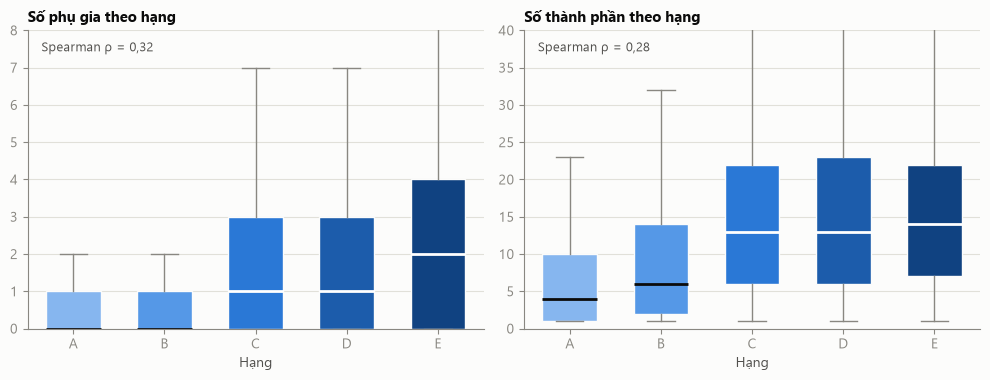

PHÁT HIỆN 7: Số phụ gia trung vị tăng từ 0 (hạng A) lên 2 (hạng E) và số thành phần trung vị từ 4 lên 14; tương quan Spearman với hạng là 0,32 (phụ gia) và 0,28 (thành phần), tức yếu đến vừa, nên hai số đếm này hữu ích nhưng không đủ để dự đoán một mình.


,additives_n,ingredients_n
nutriscore_grade,,
a,0.0,4.0
b,0.0,6.0
c,1.0,13.0
d,1.0,13.0
e,2.0,14.0


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.9))
rhos = {}
for ax, col, ttl, cap in ((axes[0], "additives_n", "Số phụ gia", 8), (axes[1], "ingredients_n", "Số thành phần", 40)):
    data = [d.loc[d["nutriscore_grade"] == g, col].dropna().astype(float).values for g in GRADES]
    bp = ax.boxplot(data, patch_artist=True, showfliers=False, widths=0.6, medianprops={"color": INK, "linewidth": 2},
                    whiskerprops={"color": MUTED}, capprops={"color": MUTED})
    for patch, c in zip(bp["boxes"], ORD):
        patch.set_facecolor(c); patch.set_edgecolor(SURFACE)
    for line, tc in zip(bp["medians"], ORD_TXT):   # trung vị: chữ trắng trên hộp đậm để còn thấy
        line.set_color(tc)
    ax.set_xticklabels([g.upper() for g in GRADES])
    ax.set_ylim(0, cap); ax.set_xlabel("Hạng"); ax.set_title(f"{ttl} theo hạng")
    ax.grid(axis="x", visible=False)
    r = stats.spearmanr(d[col].astype(float), d["g"], nan_policy="omit")
    rhos[col] = r.statistic
    meds = [np.median(x) for x in data]
    ax.text(0.03, 0.96, f"Spearman ρ = {vn(r.statistic, 2)}", transform=ax.transAxes, ha="left", va="top", fontsize=9, color=INK2)
fig.tight_layout()
save(fig, "eda_06_phu_gia_thanh_phan_theo_hang")

med = d.groupby("nutriscore_grade")[["additives_n", "ingredients_n"]].median()
finding(f"Số phụ gia trung vị tăng từ {vn(med.loc['a', 'additives_n'], 0)} (hạng A) lên {vn(med.loc['e', 'additives_n'], 0)} (hạng E) và số thành phần trung vị "
        f"từ {vn(med.loc['a', 'ingredients_n'], 0)} lên {vn(med.loc['e', 'ingredients_n'], 0)}; tương quan Spearman với hạng là {vn(rhos['additives_n'], 2)} (phụ gia) "
        f"và {vn(rhos['ingredients_n'], 2)} (thành phần), tức yếu đến vừa, nên hai số đếm này hữu ích nhưng không đủ để dự đoán một mình.")
med

## 7. NOVA so với Nutri-Score

NOVA (1-4) đo mức độ chế biến, Nutri-Score đo chất lượng dinh dưỡng; hai thước đo khác nhau nhưng liên quan. Câu hỏi nghiên cứu 3 hỏi NOVA bổ sung bao nhiêu.
Bảng chéo dưới đây cho thấy mức liên hệ; Cramér's V đo độ mạnh (0 = độc lập, 1 = hoàn toàn phụ thuộc).

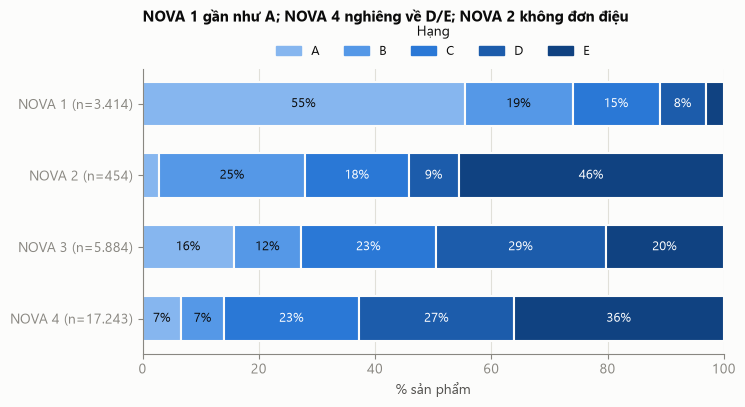

PHÁT HIỆN 8: Trong 26.995 sản phẩm có NOVA, 55,4% sản phẩm NOVA 1 đạt hạng A còn 36,1% sản phẩm NOVA 4 là hạng E; liên hệ vừa phải (Cramér's V = 0,295, Spearman ρ = 0,37, chi-bình phương p<0,001).
PHÁT HIỆN 9: Quan hệ không đơn điệu: nhóm NOVA 2 (nguyên liệu chế biến như dầu, đường, bơ) có 45,6% hạng E dù chỉ ở mức chế biến thấp, nên NOVA nên đưa vào mô hình như biến phân loại chứ không phải biến số liên tục.


nutriscore_grade,a,b,c,d,e
nova_group,,,,,
1,55.4,18.6,15.0,7.9,3.1
2,2.9,25.1,17.8,8.6,45.6
3,15.7,11.6,23.2,29.2,20.3
4,6.7,7.4,23.2,26.7,36.1


In [9]:
nv = d.dropna(subset=["nova_group"]).copy()
nv["nova_group"] = nv["nova_group"].astype(int)
ct7 = pd.crosstab(nv["nova_group"], nv["nutriscore_grade"])[GRADES]
pct7 = 100 * ct7.div(ct7.sum(axis=1), axis=0)
chi2, p, V = cramers_v(ct7)
rho = stats.spearmanr(nv["nova_group"], nv["g"]).statistic

fig, ax = plt.subplots(figsize=(7.5, 3.7))
stacked_h(ax, pct7, [f"NOVA {k} (n={vi(ct7.loc[k].sum())})" for k in pct7.index])
ax.set_title("NOVA 1 gần như A; NOVA 4 nghiêng về D/E; NOVA 2 không đơn điệu", pad=34)
save(fig, "eda_07_nova_vs_nutriscore")

finding(f"Trong {vi(len(nv))} sản phẩm có NOVA, {vn(pct7.loc[1, 'a'])}% sản phẩm NOVA 1 đạt hạng A còn {vn(pct7.loc[4, 'e'])}% sản phẩm NOVA 4 là hạng E; "
        f"liên hệ vừa phải (Cramér's V = {vn(V, 3)}, Spearman ρ = {vn(rho, 2)}, chi-bình phương p<0,001).")
finding(f"Quan hệ không đơn điệu: nhóm NOVA 2 (nguyên liệu chế biến như dầu, đường, bơ) có {vn(pct7.loc[2, 'e'])}% hạng E dù chỉ ở mức chế biến thấp, "
        f"nên NOVA nên đưa vào mô hình như biến phân loại chứ không phải biến số liên tục.")
assert p < 0.001
pct7.round(1)

## 8. Dữ liệu thiếu và mức siêu chế biến theo quốc gia

Nếu một quốc gia thiếu thương hiệu hoặc NOVA nhiều hơn, mô hình sẽ hoạt động kém hơn ở đó, và GroupKFold theo thương hiệu cũng bị ảnh hưởng.

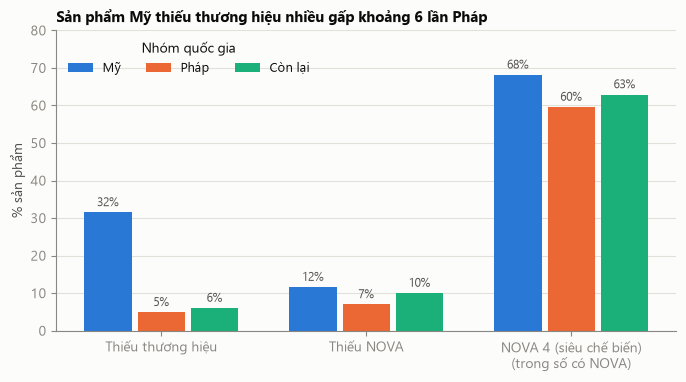

PHÁT HIỆN 10: Tỷ lệ thiếu thương hiệu là 31,5% ở Mỹ so với 4,9% ở Pháp, và thiếu NOVA là 11,6% so với 7,0%; sản phẩm Mỹ cũng nghiêng về siêu chế biến hơn (68,2% NOVA 4 so với 59,6% ở Pháp).


,Thiếu thương hiệu,Thiếu NOVA,NOVA 4 (siêu chế biến)\n(trong số có NOVA)
region,,,
Mỹ,31.5,11.6,68.2
Pháp,4.9,7.0,59.6
Còn lại,6.0,10.0,62.9


In [10]:
sub = d[d["region"].isin(REGIONS)]
met = pd.DataFrame({
    "Thiếu thương hiệu": sub.groupby("region")["flag_missing_brand"].mean(),
    "Thiếu NOVA": sub.groupby("region")["flag_missing_nova"].mean(),
    "NOVA 4 (siêu chế biến)\n(trong số có NOVA)": sub.groupby("region")["nova_group"].apply(lambda s: (s == 4).sum() / s.notna().sum()),
}).loc[REGIONS] * 100

fig, ax = plt.subplots(figsize=(8, 3.9))
w = 0.26
for i, r in enumerate(REGIONS):
    xs = np.arange(len(met.columns)) + (i - 1) * w
    ax.bar(xs, met.loc[r].values, width=w - 0.03, color=CAT[i], label=r)
    for x, v in zip(xs, met.loc[r].values):
        ax.text(x, v + 1, f"{v:.0f}%", ha="center", va="bottom", fontsize=8.5, color=INK2)
ax.set_xticks(np.arange(len(met.columns))); ax.set_xticklabels(met.columns)
ax.set_ylim(0, max(80, met.values.max() * 1.15)); ax.set_ylabel("% sản phẩm")
ax.legend(title="Nhóm quốc gia", frameon=False, ncol=3, loc="upper left", fontsize=9)
ax.set_title("Sản phẩm Mỹ thiếu thương hiệu nhiều gấp khoảng 6 lần Pháp")
ax.grid(axis="x", visible=False)
save(fig, "eda_08_thieu_du_lieu_theo_quoc_gia")

finding(f"Tỷ lệ thiếu thương hiệu là {vn(met.loc['Mỹ'].iloc[0])}% ở Mỹ so với {vn(met.loc['Pháp'].iloc[0])}% ở Pháp, và thiếu NOVA là "
        f"{vn(met.loc['Mỹ'].iloc[1])}% so với {vn(met.loc['Pháp'].iloc[1])}%; sản phẩm Mỹ cũng nghiêng về siêu chế biến hơn "
        f"({vn(met.loc['Mỹ'].iloc[2])}% NOVA 4 so với {vn(met.loc['Pháp'].iloc[2])}% ở Pháp).")
met.round(1)

## 9. Bằng chứng rò rỉ nhãn: vì sao bảng dinh dưỡng bị loại khỏi đặc trưng

Dự án mô phỏng sản phẩm **thiếu** bảng dinh dưỡng, nên đường, muối, béo bão hòa không bao giờ được là đặc trưng. Dưới đây ta chứng minh lý do: chúng (và điểm Nutri-Score) liên hệ chặt với hạng.
Phần này dùng `clean_audit.parquet`, bảng chỉ dành cho EDA.

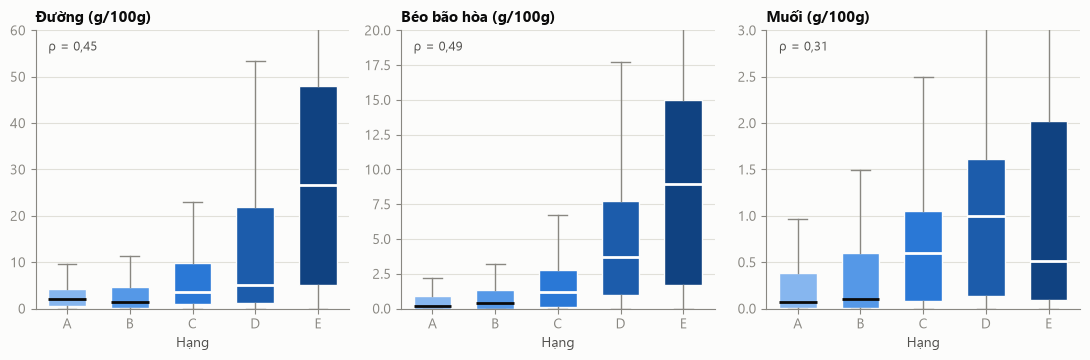

PHÁT HIỆN 11: Điểm Nutri-Score tương quan Spearman 0,95 với hạng, còn đường, béo bão hòa và muối lần lượt 0,45, 0,49 và 0,31; vì vậy bảng dinh dưỡng và điểm chỉ nằm trong bảng audit, không bao giờ làm đặc trưng.
PHÁT HIỆN 12: Rò rỉ cũng ẩn trong `labels_tags`: 1.799 sản phẩm (6,0%) in sẵn logo Nutri-Score trên bao bì và logo trùng hạng thật ở 60,9% trường hợp; cùng với các nhãn Health Star, Keyhole và cảnh báo 'exceso', Bước 4 đã bỏ các thẻ này khỏi 2.263 dòng.


,Spearman với hạng
sugars_100g,0.450
saturated-fat_100g,0.490
salt_100g,0.307
nutriscore_score,0.955


In [11]:
nut = [("sugars_100g", "Đường (g/100g)", 60), ("saturated-fat_100g", "Béo bão hòa (g/100g)", 20), ("salt_100g", "Muối (g/100g)", 3)]
fig, axes = plt.subplots(1, 3, figsize=(11, 3.7))
rho_n = {}
for ax, (col, ttl, cap) in zip(axes, nut):
    data = [d.loc[d["nutriscore_grade"] == g, col].dropna().values for g in GRADES]
    bp = ax.boxplot(data, patch_artist=True, showfliers=False, widths=0.6, medianprops={"color": INK, "linewidth": 2},
                    whiskerprops={"color": MUTED}, capprops={"color": MUTED})
    for patch, c in zip(bp["boxes"], ORD):
        patch.set_facecolor(c); patch.set_edgecolor(SURFACE)
    for line, tc in zip(bp["medians"], ORD_TXT):   # trung vị: chữ trắng trên hộp đậm để còn thấy
        line.set_color(tc)
    ax.set_xticklabels([g.upper() for g in GRADES]); ax.set_ylim(0, cap); ax.set_xlabel("Hạng"); ax.set_title(ttl)
    ax.grid(axis="x", visible=False)
    rho_n[col] = stats.spearmanr(d[col], d["g"], nan_policy="omit").statistic
    ax.text(0.04, 0.96, f"ρ = {vn(rho_n[col], 2)}", transform=ax.transAxes, ha="left", va="top", fontsize=9, color=INK2)
fig.tight_layout()
save(fig, "eda_09_ro_ri_dinh_duong")

rho_score = stats.spearmanr(d["nutriscore_score"], d["g"]).statistic
sf = pd.read_parquet("data/processed/staging_features.parquet", columns=["row_id", "labels_tags"]).merge(
    y[["row_id", "nutriscore_grade"]], on="row_id")


def logo(v):
    for t in (v if v is not None else []):
        m = re.match(r"^en:nutriscore-grade-([a-e])$", t)
        if m:
            return m.group(1)
    return None


sf["logo"] = sf["labels_tags"].map(logo)
has_logo = sf["logo"].notna()
match_logo = (sf.loc[has_logo, "logo"] == sf.loc[has_logo, "nutriscore_grade"]).mean()
import json
removed = json.load(open("reports/cleaning_report.json", encoding="utf-8"))["normalization"]["rows_with_leaky_labels_removed"]

finding(f"Điểm Nutri-Score tương quan Spearman {vn(rho_score, 2)} với hạng, còn đường, béo bão hòa và muối lần lượt {vn(rho_n['sugars_100g'], 2)}, "
        f"{vn(rho_n['saturated-fat_100g'], 2)} và {vn(rho_n['salt_100g'], 2)}; vì vậy bảng dinh dưỡng và điểm chỉ nằm trong bảng audit, không bao giờ làm đặc trưng.")
finding(f"Rò rỉ cũng ẩn trong `labels_tags`: {vi(has_logo.sum())} sản phẩm ({vn(100 * has_logo.mean())}%) in sẵn logo Nutri-Score trên bao bì và logo trùng hạng thật ở "
        f"{vn(100 * match_logo)}% trường hợp; cùng với các nhãn Health Star, Keyhole và cảnh báo 'exceso', Bước 4 đã bỏ các thẻ này khỏi {vi(removed)} dòng.")
pd.DataFrame({"Spearman với hạng": {**rho_n, "nutriscore_score": rho_score}}).round(3)

## 10. Cờ chất lượng gắn với nhãn như thế nào

Các cờ `flag_few_ingredients`, `flag_missing_nova` không dùng để loại dòng, nhưng nếu chúng liên hệ với hạng thì mô hình sẽ học "mẫu thiếu dữ liệu" thay vì học dinh dưỡng,
và đó là một dạng thiên lệch cần ghi vào hạn chế.

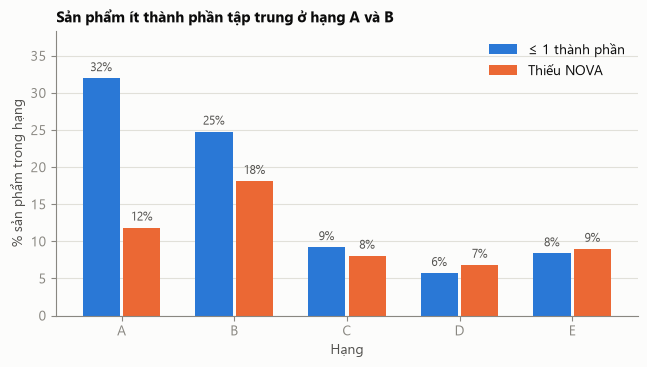

PHÁT HIỆN 13: Sản phẩm chỉ có ≤ 1 thành phần chiếm 32,0% hạng A và 24,8% hạng B nhưng chỉ 5,7% hạng D; riêng hạng B thiếu NOVA tới 18,1% so với 6,8% hạng D, nên việc thiếu dữ liệu tự nó mang thông tin về nhãn và phải ghi vào phần hạn chế (3.981 sản phẩm bị gắn cờ ít thành phần).


,flag_few_ingredients,flag_missing_nova
nutriscore_grade,,
a,32.0,11.9
b,24.8,18.1
c,9.2,8.1
d,5.7,6.8
e,8.4,9.0


In [12]:
fl = d.groupby("nutriscore_grade")[["flag_few_ingredients", "flag_missing_nova"]].mean().reindex(GRADES) * 100
fig, ax = plt.subplots(figsize=(7.5, 3.7))
w = 0.36
for j, (col, lab, c) in enumerate((("flag_few_ingredients", "≤ 1 thành phần", CAT[0]), ("flag_missing_nova", "Thiếu NOVA", CAT[1]))):
    xs = np.arange(5) + (j - 0.5) * w
    ax.bar(xs, fl[col].values, width=w - 0.03, color=c, label=lab)
    for x, v in zip(xs, fl[col].values):
        ax.text(x, v + 0.6, f"{v:.0f}%", ha="center", va="bottom", fontsize=8.5, color=INK2)
ax.set_xticks(range(5)); ax.set_xticklabels([g.upper() for g in GRADES])
ax.set_xlabel("Hạng"); ax.set_ylabel("% sản phẩm trong hạng"); ax.set_ylim(0, fl.values.max() * 1.2)
ax.legend(frameon=False, loc="upper right")
ax.set_title("Sản phẩm ít thành phần tập trung ở hạng A và B")
ax.grid(axis="x", visible=False)
save(fig, "eda_10_co_chat_luong_theo_hang")

n_few = int(d["flag_few_ingredients"].sum())
finding(f"Sản phẩm chỉ có ≤ 1 thành phần chiếm {vn(fl.loc['a', 'flag_few_ingredients'])}% hạng A và {vn(fl.loc['b', 'flag_few_ingredients'])}% hạng B nhưng chỉ "
        f"{vn(fl.loc['d', 'flag_few_ingredients'])}% hạng D; riêng hạng B thiếu NOVA tới {vn(fl.loc['b', 'flag_missing_nova'])}% so với {vn(fl.loc['d', 'flag_missing_nova'])}% hạng D, "
        f"nên việc thiếu dữ liệu tự nó mang thông tin về nhãn và phải ghi vào phần hạn chế ({vi(n_few)} sản phẩm bị gắn cờ ít thành phần).")
fl.round(1)

## 11. Nhóm sản phẩm nào khó dự đoán nhất? (giả thuyết cho câu hỏi nghiên cứu 1)

Dùng **entropy chuẩn hóa** của phân bố hạng trong từng nhóm `pnns_groups_2` làm thước đo "độ khó dự kiến": 0 nghĩa là cả nhóm cùng một hạng (dễ đoán),
1 nghĩa là hạng phân bố đều khắp A-E (khó đoán). Đây mới là chỉ báo sơ bộ từ dữ liệu; độ khó thực sự đo bằng mô hình ở Bước 9.

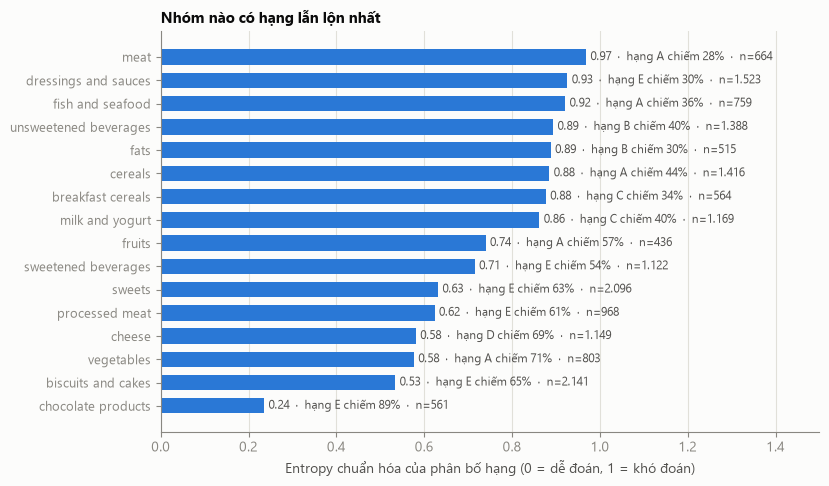

PHÁT HIỆN 14: Trong các nhóm có từ 400 sản phẩm, 'meat' (entropy 0,97) và 'dressings and sauces' (0,93) có hạng lẫn lộn nhất, còn 'chocolate products' (0,24) gần như đồng nhất; chỉ cần đoán hạng phổ biến nhất trong từng nhóm `pnns_groups_2` đã đạt 50,5% độ chính xác (so với 28,4% nếu đoán một hạng cho tất cả), đây là mốc đường cơ sở cho Bước 7.


,n,H,top_share,top_grade
pnns_groups_2,,,,
meat,664,0.968,0.282,a
dressings and sauces,1523,0.926,0.303,e
fish and seafood,759,0.921,0.357,a
unsweetened beverages,1388,0.894,0.397,b
fats,515,0.888,0.299,b
cereals,1416,0.885,0.436,a
breakfast cereals,564,0.877,0.342,c
milk and yogurt,1169,0.862,0.399,c
one dish meals,1333,0.853,0.488,c


In [13]:
p2 = d.dropna(subset=["pnns_groups_2"])


def norm_entropy(s):
    p = s.value_counts(normalize=True)
    return float(-(p * np.log2(p)).sum() / np.log2(5))


grp = p2.groupby("pnns_groups_2").agg(n=("g", "size"), H=("nutriscore_grade", norm_entropy),
                                      top_share=("nutriscore_grade", lambda s: s.value_counts(normalize=True).iloc[0]),
                                      top_grade=("nutriscore_grade", lambda s: s.value_counts().index[0]))
grp = grp[grp["n"] >= 400].sort_values("H", ascending=False)
sel = pd.concat([grp.head(8), grp.tail(8)]).drop_duplicates()

fig, ax = plt.subplots(figsize=(8.5, 5.2))
ax.barh(range(len(sel)), sel["H"].values, color=CAT[0], height=0.66)
for i, (_, r) in enumerate(sel.iterrows()):
    ax.text(r["H"] + 0.01, i, f"{r['H']:.2f}  ·  hạng {r['top_grade'].upper()} chiếm {100 * r['top_share']:.0f}%  ·  n={vi(r['n'])}",
            va="center", fontsize=8.5, color=INK2)
ax.set_yticks(range(len(sel))); ax.set_yticklabels(sel.index, fontsize=9)
ax.invert_yaxis(); ax.set_xlim(0, 1.5); ax.set_xlabel("Entropy chuẩn hóa của phân bố hạng (0 = dễ đoán, 1 = khó đoán)")
ax.set_title("Nhóm nào có hạng lẫn lộn nhất")
ax.grid(axis="y", visible=False)
save(fig, "eda_11_do_kho_theo_nhom")

major_acc = p2.groupby("pnns_groups_2")["nutriscore_grade"].agg(lambda s: s.value_counts().iloc[0]).sum() / len(p2)
global_major = d["nutriscore_grade"].value_counts(normalize=True).iloc[0]
finding(f"Trong các nhóm có từ 400 sản phẩm, '{grp.index[0]}' (entropy {vn(grp['H'].iloc[0], 2)}) và '{grp.index[1]}' ({vn(grp['H'].iloc[1], 2)}) có hạng lẫn lộn nhất, "
        f"còn '{grp.index[-1]}' ({vn(grp['H'].iloc[-1], 2)}) gần như đồng nhất; chỉ cần đoán hạng phổ biến nhất trong từng nhóm `pnns_groups_2` đã đạt {vn(100 * major_acc)}% độ chính xác "
        f"(so với {vn(100 * global_major)}% nếu đoán một hạng cho tất cả), đây là mốc đường cơ sở cho Bước 7.")
grp.round(3)

## Tổng hợp các phát hiện

Bảng dưới là các câu kết luận có số liệu (chép sang `docs/eda_findings.md`).

In [14]:
for i, t in enumerate(FINDINGS, 1):
    print(f"{i}. {t}\n")
print(f"Tổng: {len(FINDINGS)} phát hiện, {len(list((ROOT / 'reports' / 'figures').glob('eda_*.png')))} biểu đồ trong reports/figures/")

1. Trong 29.904 sản phẩm, hạng E chiếm nhiều nhất (28,4%, 8.497 sản phẩm) và hạng B ít nhất (11,0%, 3.296); lớp lớn nhất gấp 2,6 lần lớp nhỏ nhất, mất cân bằng nhẹ nên dùng trọng số lớp và F1 trung bình theo lớp.

2. Tỷ lệ hạng E là 33,0% ở Mỹ, 26,6% ở Pháp và 24,7% ở nhóm còn lại; khác biệt có ý nghĩa thống kê (chi-bình phương p<0,001) nhưng mức liên hệ nhỏ (Cramér's V = 0,063). 121 sản phẩm bán ở cả hai nước được loại khỏi phép so sánh này.

3. Nhóm 'sugary snacks' có 91,5% sản phẩm hạng D/E trong khi nhóm 'fruits and vegetables' chỉ 12,8%; nhưng 5.966 sản phẩm (20,0%) không có `pnns_groups_1`, nên đặc trưng danh mục cần xử lý giá trị thiếu (dùng `categories_tags` bổ sung).

4. Có 53.793 thẻ thành phần khác nhau, trong đó 84,1% chỉ xuất hiện đúng 1 lần và 93,7% dưới 5 lần; chỉ 1.491 thẻ có từ 20 sản phẩm và 627 thẻ từ 100 sản phẩm, nên Bước 6 cần ngưỡng tần suất tối thiểu (các thẻ ≥100 vẫn phủ 95,7% sản phẩm).

5. Với P(D/E) chung = 52,2%, các thành phần có lift cao nhất gồm e127, mi